# Regressão linear múltipla — Usina de ciclo combinado

**PAM0466 – Sistemas Inteligentes · Problema 1**

# Conjunto de dados
- **AT** (Ambient Temperature): temperatura em °C. Afeta a densidade do ar e a eficiência da combustão
- **V** (Exhaust Vacuum): vácuo de escape em cm Hg. Relacionado à pressão na turbina a vapor
- **AP** (Ambient Pressure): pressão atmosférica em mbar
- **RH** (Relative Humidity): umidade relativa em porcentagem
- **PE** (Net Hourly Electrical Energy Output): a variável alvo, em MW (megawatts)

In [1]:
import pandas as pd


df = pd.read_excel('UCI CCPP.xlsx')

print(df.shape)
df.head()

(9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [2]:
# visualizar o total de nulos por variável
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [3]:

df.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


Não há valores nulos, então não é necessário imputar nada. (Mesmo assim, o pré-processamento de dados ausentes fica registrado aqui: `df.isnull().sum()` = 0 em todas as colunas.)

# 1 - Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) e a variável dependente (PE). Quais variáveis parecem ter maior influência na produção de energia?

In [4]:

x = df.drop(columns=['PE'])
y = df['PE']

# correlação de Pearson entre cada variável de x e y
correlacao_x_y = x.corrwith(y)
print(correlacao_x_y)


print()
print(x.corrwith(y, method='spearman'))

AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
dtype: float64

AT   -0.944412
V    -0.883702
AP    0.542531
RH    0.389640
dtype: float64


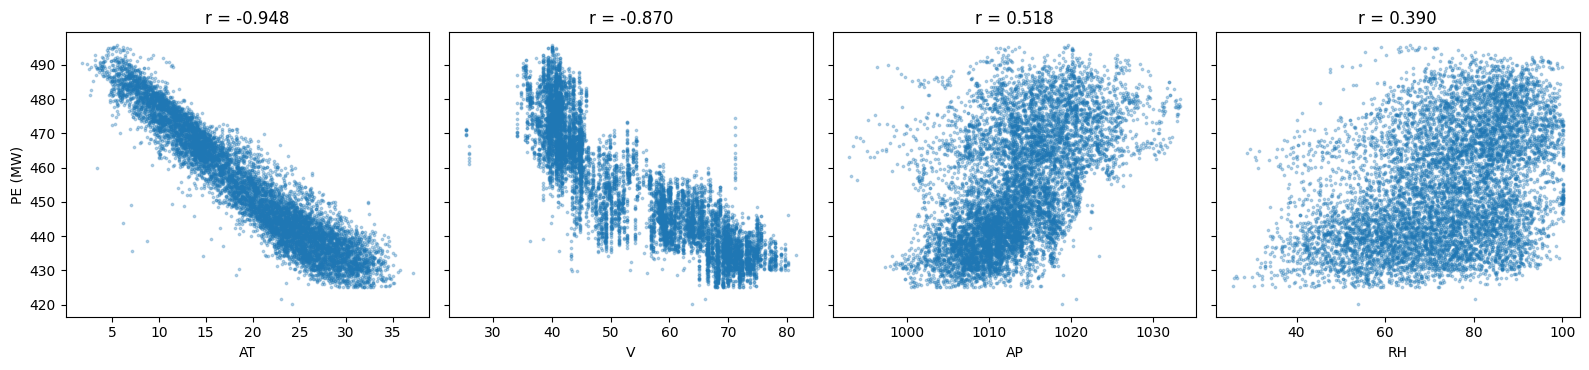

In [5]:
import matplotlib.pyplot as plt

# gráfico de dispersão de cada variável contra PE
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for eixo, coluna in zip(eixos, x.columns):
    eixo.scatter(x[coluna], y, s=3, alpha=0.3)
    eixo.set_xlabel(coluna)
    eixo.set_title(f'r = {correlacao_x_y[coluna]:.3f}')
eixos[0].set_ylabel('PE (MW)')
plt.tight_layout()
plt.show()

| Variável | Correlação de Pearson com PE | Spearman | Posição |
|:---|---:|---:|:---|
| AT | −0,948 | −0,944 | Top 1 |
| V | −0,870 | −0,884 | Top 2 |
| AP | +0,518 | +0,543 | Top 3 |
| RH | +0,390 | +0,390 | Top 4 |

As variáveis de maior influência são **AT** (temperatura) e **V** (vácuo de escape), com correlação negativa e forte: quanto maior a temperatura e o vácuo, menor a produção de energia. Isso faz sentido fisicamente, pois ar mais quente é menos denso e reduz a eficiência da combustão. AP e RH têm correlação positiva e moderada. Pearson e Spearman deram valores quase iguais, o que indica que a relação é aproximadamente linear.

# 2 - Calcule a correlação entre as variáveis independentes (AT, V, AP, RH) entre si. Existe alguma relação forte entre elas? Se sim, isso pode indicar multicolinearidade.

In [6]:
# correlação entre as variáveis independentes
correlacao_x = x.corr()
print(correlacao_x)

          AT         V        AP        RH
AT  1.000000  0.844107 -0.507549 -0.542535
V   0.844107  1.000000 -0.413502 -0.312187
AP -0.507549 -0.413502  1.000000  0.099574
RH -0.542535 -0.312187  0.099574  1.000000


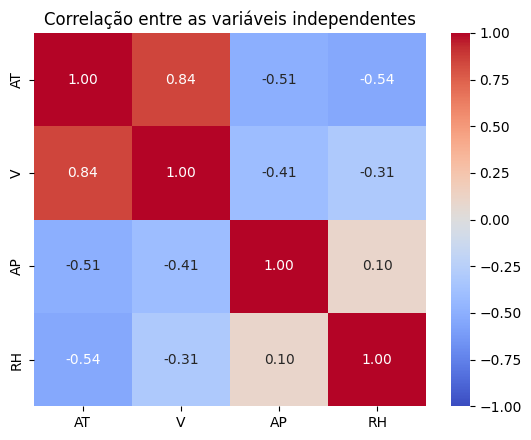

In [7]:
import seaborn as sns

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(correlacao_x, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlação entre as variáveis independentes')
plt.tight_layout()
plt.show()

Regra prática

|Correlação|Interpretação|
|:---|:---|
|> 0,8 ou < -0,8|Forte|
|0,5 a 0,8 (em módulo)|Moderada|
|< 0,5|Fraca|

Para quantificar a multicolinearidade usamos o **fator de inflação da variância (VIF)**: $VIF_j = \frac{1}{1 - R_j^2}$, em que $R_j^2$ é o R² da regressão da variável $j$ contra as demais. Regra prática: VIF > 5 pede atenção e VIF > 10 indica problema sério.

In [8]:
from sklearn.linear_model import LinearRegression

for coluna in x.columns:
    outras = x.drop(columns=[coluna])
    r2 = LinearRegression().fit(outras, x[coluna]).score(outras, x[coluna])
    print(f'VIF de {coluna}: {1 / (1 - r2):.2f}')

VIF de AT: 5.98
VIF de V: 3.94
VIF de AP: 1.45
VIF de RH: 1.71


| | AT | V | AP | RH |
|:---|---:|---:|---:|---:|
| AT | 1,00 | **0,84** | −0,51 | −0,54 |
| V | 0,84 | 1,00 | −0,41 | −0,31 |
| AP | −0,51 | −0,41 | 1,00 | 0,10 |
| RH | −0,54 | −0,31 | 0,10 | 1,00 |

VIF: **AT = 5,98**, V = 3,94, AP = 1,45, RH = 1,71.

Sim, **AT e V** têm correlação forte entre si (r = 0,84), e AT também se relaciona de forma moderada com RH (−0,54) e AP (−0,51). Isso indica **multicolinearidade moderada**: o VIF de AT passa de 5, mas fica abaixo de 10, então não é grave. A multicolinearidade deixa os coeficientes individuais de AT e V menos estáveis e mais difíceis de interpretar, mas quase não afeta a capacidade de previsão: ao retirar V, o R² no teste cai só de 0,9301 para 0,9219.

# 3 - Construa um modelo de regressão linear múltipla utilizando as variáveis independentes (AT, V, AP, RH) para prever a variável dependente (PE). Divida os dados em treino (80%) e teste (20%).

Como temos mais de uma variável independente, usamos a regressão linear múltipla

$$
y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_p x_p + \epsilon
$$

em que:

- $x_1, ..., x_p$ são as variáveis independentes (features);
- $y$ é a variável dependente (valor que queremos prever);
- $\theta_0$ é o intercepto;
- $\theta_1, ..., \theta_p$ são os coeficientes, o impacto de cada variável em $y$;
- $\epsilon$ é o erro (resíduo) da aproximação.

As variáveis têm escalas muito diferentes (AP ≈ 1000 mbar contra AT ≈ 20 °C), então vamos padronizar com **z-score**:

$$ z = \frac{x - \mu}{\sigma} $$

A divisão treino/teste vem **antes** da padronização, e o `StandardScaler` aprende $\mu$ e $\sigma$ só no treino (`fit`), para não vazar informação do teste.

In [9]:
from sklearn.model_selection import train_test_split

# dividindo os dados em treino e teste
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,    # 20% teste e 80% treino
    random_state=42   # garante que a divisão seja sempre a mesma
)

print(f"Tamanho do dataset: {len(df)}")
print(f"Tamanho do dataset de treino: {len(x_train)}")
print(f"Tamanho do dataset de teste: {len(x_test)}")

Tamanho do dataset: 9568
Tamanho do dataset de treino: 7654
Tamanho do dataset de teste: 1914


In [10]:
from sklearn.preprocessing import StandardScaler

# padronização z-score
scaler = StandardScaler()
x_train_z = scaler.fit_transform(x_train)   # fit() calcula média e desvio padrão (só no treino) e transform() aplica a fórmula
x_test_z = scaler.transform(x_test)         # no teste só aplicamos (transform) com a média e o desvio do treino

print('Média no treino (≈ 0):', x_train_z.mean(axis=0).round(4))
print('Desvio no treino (= 1):', x_train_z.std(axis=0).round(4))

Média no treino (≈ 0): [-0. -0. -0.  0.]
Desvio no treino (= 1): [1. 1. 1. 1.]


In [11]:
# treinando o modelo de regressão linear
model = LinearRegression()
model.fit(x_train_z, y_train)

print('Intercepto (theta0):', round(model.intercept_, 4))
for nome, theta in zip(x.columns, model.coef_):
    print(f'theta {nome}: {theta:.4f}')

Intercepto (theta0): 454.431
theta AT: -14.7639
theta V: -2.9496
theta AP: 0.3698
theta RH: -2.3122


Esses coeficientes estão na escala padronizada (por 1 desvio padrão da variável), então servem para comparar a importância. Para a equação em unidades originais, ajustamos o mesmo modelo nos dados sem padronizar:

In [12]:

model_original = LinearRegression()
model_original.fit(x_train, y_train)

print('theta0 =', round(model_original.intercept_, 4))
for nome, theta in zip(x.columns, model_original.coef_):
    print(f'theta {nome} = {theta:.4f}')

import numpy as np
print('Previsões iguais:', np.allclose(model.predict(x_test_z), model_original.predict(x_test)))

theta0 = 454.5691
theta AT = -1.9859
theta V = -0.2321
theta AP = 0.0622
theta RH = -0.1581
Previsões iguais: True


In [13]:
# conferindo com a equação normal: theta = (X'X)^-1 X'y
import numpy as np

X_b = np.c_[np.ones(len(x_train)), x_train.values]        # coluna de 1s para o intercepto
theta_normal = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y_train.values
print('Equação normal:', theta_normal.round(4))
print('scikit-learn  :', np.r_[model_original.intercept_, model_original.coef_].round(4))

Equação normal: [ 4.545691e+02 -1.985900e+00 -2.321000e-01  6.220000e-02 -1.581000e-01]
scikit-learn  : [ 4.545691e+02 -1.985900e+00 -2.321000e-01  6.220000e-02 -1.581000e-01]


Coeficientes do modelo (treino com 7.654 amostras):

| Variável | Coeficiente padronizado | Coeficiente na unidade original |
|:---|---:|---:|
| AT | −14,764 | −1,9859 MW/°C |
| V | −2,950 | −0,2321 MW/cmHg |
| AP | +0,370 | +0,0622 MW/mbar |
| RH | −2,312 | −0,1581 MW/% |

$$ \hat{PE} = 454{,}569 - 1{,}9859\,AT - 0{,}2321\,V + 0{,}0622\,AP - 0{,}1581\,RH $$

Os coeficientes da equação normal $\theta = (X^TX)^{-1}X^Ty$ deram exatamente os mesmos do scikit-learn, e o modelo padronizado e o modelo em unidades originais fazem as mesmas previsões.

Interpretando: mantendo as outras variáveis fixas, cada +1 °C em AT reduz a produção em cerca de 1,99 MW. Na escala padronizada, AT domina (|−14,76|), seguida de V e RH; AP tem efeito pequeno. Note que RH tem correlação **positiva** com PE sozinha (+0,39), mas coeficiente **negativo** no modelo múltiplo: isso acontece porque RH é maior em dias frios (r com AT = −0,54) e dias frios produzem mais energia; descontando o efeito de AT, o efeito próprio de RH é levemente negativo. É um exemplo de como a multicolinearidade pode inverter o sinal de um coeficiente.

# 4 - Avalie o desempenho do modelo utilizando métricas como R², RMSE e MAE. O modelo é adequado para prever a produção de energia? Justifique sua resposta.

Fórmulas

$$
R^2 = 1 - \frac{SQR}{SQT} = 1 - \frac{\sum (y^{(i)} - \hat{y}^{(i)})^2}{\sum (y^{(i)} - \bar{y})^2}
$$

- **SQR**: soma dos quadrados dos resíduos, a variação que o modelo não explicou
- **SQT**: soma total dos quadrados, a variação dos dados em relação à média

$$ MSE = \frac{1}{N}\sum (y^{(i)} - \hat{y}^{(i)})^2 \qquad RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{N}\sum |y^{(i)} - \hat{y}^{(i)}| $$

Interpretação prática do $R^2$

|Situação|Diagnóstico|
|:---|:---|
|Treino alto, teste baixo|Overfitting|
|Treino ≈ teste|Modelo bom|
|Ambos baixos|Modelo ruim|

|R²|Satisfação|
|:---|:---|
|> 0,8|Modelo muito bom|
|0,6 a 0,8|Razoável|
|< 0,5|Fraco|

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# previsões
y_pred_train = model.predict(x_train_z)
y_pred_test = model.predict(x_test_z)

# métricas no treino e no teste
for nome, y_real, y_prev in [('Treino', y_train, y_pred_train), ('Teste', y_test, y_pred_test)]:
    mse = mean_squared_error(y_real, y_prev)
    print(f"{nome}:")
    print(f"  R2   = {r2_score(y_real, y_prev):.4f}")
    print(f"  MSE  = {mse:.4f}")
    print(f"  RMSE = {np.sqrt(mse):.4f} MW")
    print(f"  MAE  = {mean_absolute_error(y_real, y_prev):.4f} MW")

Treino:
  R2   = 0.9283
  MSE  = 20.8934
  RMSE = 4.5709 MW
  MAE  = 3.6300 MW
Teste:
  R2   = 0.9301
  MSE  = 20.2737
  RMSE = 4.5026 MW
  MAE  = 3.5959 MW


In [15]:
from sklearn.dummy import DummyRegressor


baseline = DummyRegressor(strategy='mean').fit(x_train_z, y_train)
y_base = baseline.predict(x_test_z)
print(f"Baseline - R2 = {r2_score(y_test, y_base):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, y_base)):.4f} MW | MAE = {mean_absolute_error(y_test, y_base):.4f} MW")

Baseline - R2 = -0.0004 | RMSE = 17.0343 MW | MAE = 14.8067 MW


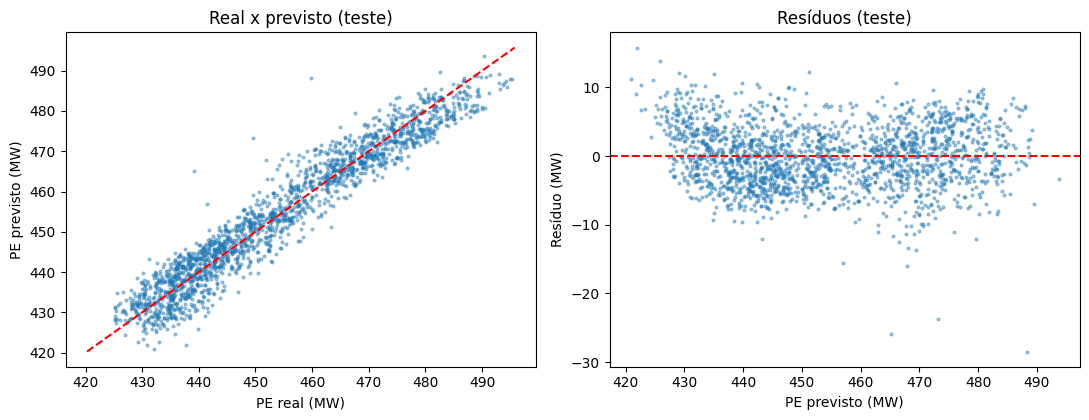

Resíduo médio: -0.0394 MW | maior erro absoluto: 28.46 MW


In [16]:
# gráficos: valores reais x previstos e resíduos (teste)
residuos = y_test - y_pred_test

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.3))
eixos[0].scatter(y_test, y_pred_test, s=4, alpha=0.4)
eixos[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
eixos[0].set_xlabel('PE real (MW)'); eixos[0].set_ylabel('PE previsto (MW)'); eixos[0].set_title('Real x previsto (teste)')
eixos[1].scatter(y_pred_test, residuos, s=4, alpha=0.4)
eixos[1].axhline(0, color='r', ls='--')
eixos[1].set_xlabel('PE previsto (MW)'); eixos[1].set_ylabel('Resíduo (MW)'); eixos[1].set_title('Resíduos (teste)')
plt.tight_layout()
plt.show()

print(f"Resíduo médio: {residuos.mean():.4f} MW | maior erro absoluto: {residuos.abs().max():.2f} MW")

In [17]:
# validação cruzada (5 folds) para ver se o R2 é estável
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), LinearRegression())
scores = cross_val_score(pipe, x_train, y_train, cv=5, scoring='r2')
print('R2 por fold:', scores.round(4))
print(f'Média = {scores.mean():.4f} | desvio = {scores.std():.4f}')


x_sem_v_train, x_sem_v_test = x_train.drop(columns=['V']), x_test.drop(columns=['V'])
sem_v = make_pipeline(StandardScaler(), LinearRegression()).fit(x_sem_v_train, y_train)
p = sem_v.predict(x_sem_v_test)
print(f"Sem V: R2 teste = {r2_score(y_test, p):.4f} | RMSE = {np.sqrt(mean_squared_error(y_test, p)):.4f}")

R2 por fold: [0.926  0.9241 0.9331 0.9293 0.9286]
Média = 0.9282 | desvio = 0.0031
Sem V: R2 teste = 0.9219 | RMSE = 4.7598


| Conjunto | R² | RMSE (MW) | MAE (MW) |
|:---|---:|---:|---:|
| Treino | 0,9283 | 4,571 | 3,630 |
| Teste | **0,9301** | **4,503** | **3,596** |
| Baseline (sempre a média) | −0,0004 | 17,034 | 14,807 |

Validação cruzada (5 folds): R² = 0,9282 ± 0,0031.

**O modelo é adequado?** Sim. Pela tabela de satisfação, R² > 0,8 é um modelo muito bom; aqui o modelo explica ≈ 93% da variação de PE. O R² de treino (0,928) é praticamente igual ao de teste (0,930), então **não há overfitting**, e a validação cruzada confirma a estabilidade. O erro típico é de ≈ 4,5 MW (RMSE) e 3,6 MW (MAE), contra 17 MW do baseline, para uma variável que varia de 420 a 496 MW (desvio padrão de 17 MW), ou seja, um erro de menos de 1% do valor médio (454 MW). Como limitação, o maior erro absoluto no teste chega a 28 MW; modelos não lineares poderiam reduzir os erros maiores. Para o despacho energético, porém, a precisão obtida é adequada.